# 17 · Trustworthy Confidence: Calibration and Conformal Prediction Sets

**The questions:**
1. When the detector says "90% sure", is it right about 90% of the time? (**calibration**)
2. Can the detector say honestly **"Analysis or Backdoor, I can't tell"** for the flows whose labels are ambiguous? (**conformal prediction sets**)

| | |
|---|---|
| **Input** | The final detector; the reserved **`calibration`** rows (17,534, untouched until now); `model_selection` rows for checking |
| **What we do** | Fit a temperature and conformal thresholds on the calibration rows only, then check them on `model_selection` |
| **Output** | Calibrated probabilities, class-wise prediction sets with a coverage guarantee, and an abstention rule for analysts |

This answers research question **RQ4**: can prediction sets express the label ambiguity found in Notebook 02, while keeping their promised coverage?

## 1. Setup

In [1]:
import sys
import warnings
from pathlib import Path
sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src').is_dir())))
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.optimize import minimize_scalar
from sklearn.metrics import f1_score

from src.notebook_helpers import TRAIN_CSV, RAW_SHA256, CLASSES, DATA, MODELS, sha256, save_table, save_figure, save_json, setup_style
from src.final_detector import FinalDetector, apply_temperature, prediction_sets, load_raw
setup_style()
assert sha256(TRAIN_CSV) == RAW_SHA256['train']

detector = FinalDetector.load()
detector.temperature = 1.0                      # start uncalibrated; this notebook fits the temperature
print('Final detector:', detector.name)
raw = {r: load_raw(r) for r in ['calibration', 'model_selection']}
y = {r: pd.Categorical(f.attack_cat, categories=CLASSES).codes.astype(int) for r, f in raw.items()}
p_raw = {r: detector.predict_proba(f, calibrated=False) for r, f in raw.items()}
print({r: p.shape for r, p in p_raw.items()})

Final detector: LightGBM (sqrt)


{'calibration': (17534, 10), 'model_selection': (17534, 10)}


## 2. Is the detector calibrated?

**Expected calibration error (ECE):** group predictions by their confidence (0-10%, 10-20%, ...), compare the average confidence in each group with
the share that was actually correct, and average the gaps. 0 means perfectly calibrated.

In [2]:
def ece(proba, y_true, bins=15):
    confidence, correct = proba.max(1), proba.argmax(1) == y_true
    edges = np.linspace(0, 1, bins + 1)
    total = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        in_bin = (confidence > lo) & (confidence <= hi)
        if in_bin.any():
            total += in_bin.mean() * abs(confidence[in_bin].mean() - correct[in_bin].mean())
    return total


def nll(proba, y_true):
    return float(-np.log(np.clip(proba[np.arange(len(y_true)), y_true], 1e-12, 1)).mean())


print(f"before calibration, model_selection: ECE {ece(p_raw['model_selection'], y['model_selection']):.4f} | "
      f"log-loss {nll(p_raw['model_selection'], y['model_selection']):.4f}")

before calibration, model_selection: ECE 0.0091 | log-loss 0.4381


## 3. Temperature scaling (fitted on the calibration rows only)

One number, the **temperature T**, softens (T > 1) or sharpens (T < 1) all probabilities. It is chosen to make the probabilities of the true classes as
high as possible on the calibration rows (lowest log-loss). It never changes which class is predicted, so macro F1 stays exactly the same.

In [3]:
fit = minimize_scalar(lambda t: nll(apply_temperature(p_raw['calibration'], t), y['calibration']), bounds=(0.05, 20), method='bounded')
T = float(fit.x)
p_cal = {r: apply_temperature(p, T) for r, p in p_raw.items()}
assert (p_cal['model_selection'].argmax(1) == p_raw['model_selection'].argmax(1)).all()

calibration_table = pd.DataFrame({
    'ECE before': [ece(p_raw[r], y[r]) for r in raw], 'ECE after': [ece(p_cal[r], y[r]) for r in raw],
    'log-loss before': [nll(p_raw[r], y[r]) for r in raw], 'log-loss after': [nll(p_cal[r], y[r]) for r in raw],
    'macro F1 (unchanged)': [f1_score(y[r], p_cal[r].argmax(1), average='macro', labels=range(10)) for r in raw]}, index=list(raw))
save_table(calibration_table, '17_calibration', index=True)
print(f'fitted temperature T = {T:.3f}')
display(calibration_table)

fitted temperature T = 1.001


,ECE before,ECE after,log-loss before,log-loss after,macro F1 (unchanged)
calibration,0.0137,0.0136,0.4470,0.4470,0.6399
model_selection,0.0091,0.0089,0.4381,0.4381,0.6662


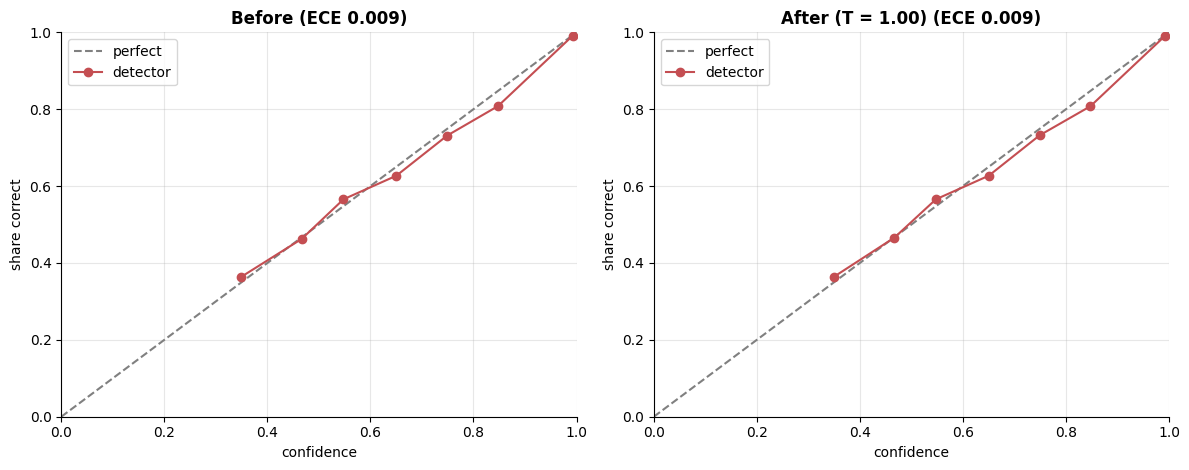

In [4]:
def reliability(ax, proba, y_true, title, bins=10):
    confidence, correct = proba.max(1), proba.argmax(1) == y_true
    edges = np.linspace(0, 1, bins + 1)
    mids, acc, conf, counts = [], [], [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        in_bin = (confidence > lo) & (confidence <= hi)
        if in_bin.sum() >= 20:
            mids.append((lo + hi) / 2); acc.append(correct[in_bin].mean()); conf.append(confidence[in_bin].mean()); counts.append(in_bin.sum())
    ax.plot([0, 1], [0, 1], '--', color='grey', label='perfect')
    ax.plot(conf, acc, 'o-', color='#C44E52', label='detector')
    ax.set(xlabel='confidence', ylabel='share correct', title=f'{title} (ECE {ece(proba, y_true):.3f})', xlim=(0, 1), ylim=(0, 1)); ax.legend()


fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
reliability(axes[0], p_raw['model_selection'], y['model_selection'], 'Before')
reliability(axes[1], p_cal['model_selection'], y['model_selection'], f'After (T = {T:.2f})')
plt.tight_layout(); save_figure(fig, '17_reliability'); plt.show()

**What we see:**

- **LightGBM (sqrt) is already well calibrated:** ECE 0.009 on `model_selection` and 0.014 on the calibration rows. The reliability curve lies close to
  the diagonal.
- The fitted temperature is **T = 1.001**, which changes the probabilities only in the fourth decimal (ECE 0.0091 → 0.0089). Temperature scaling is kept
  in the pipeline because it costs nothing and would correct a less-calibrated model, but here its effect is negligible.
- Macro F1 is unchanged (0.666), as expected.

## 4. Conformal prediction sets

Instead of one answer, the detector returns a **set of classes** that is guaranteed to contain the true class for at least **90%** of flows
(error level α = 0.10). The guarantee comes from a simple rule, fitted on the calibration rows:

1. For each calibration row, compute a "surprise" score: 1 − (probability given to its true class).
2. For each class, find the score that 90% of its calibration rows stay below (a slightly corrected 90th percentile).
3. For a new flow, include every class whose probability is high enough to pass its class threshold.

We fit the thresholds **per class** ("class-conditional" or Mondrian conformal), so rare classes also get their 90% coverage, not just the big ones.
For comparison we also fit one shared threshold for all classes.

In [5]:
ALPHA = 0.10


def conformal_threshold(scores, alpha):
    n = len(scores)
    level = min(1.0, np.ceil((n + 1) * (1 - alpha)) / n)
    return float(np.quantile(scores, level, method='higher'))


scores_cal = 1 - p_cal['calibration'][np.arange(len(y['calibration'])), y['calibration']]
class_q = np.array([conformal_threshold(scores_cal[y['calibration'] == k], ALPHA) for k in range(10)])
shared_q = conformal_threshold(scores_cal, ALPHA)
thresholds = {'class-conditional': 1 - class_q, 'shared': np.full(10, 1 - shared_q)}
display(pd.DataFrame({'calibration rows': np.bincount(y['calibration'], minlength=10), 'class threshold (min probability)': 1 - class_q},
                     index=CLASSES).round(4))

,calibration rows,class threshold (min probability)
Analysis,200,0.0955
Backdoor,174,0.0587
DoS,1227,0.1785
Exploits,3339,0.2368
Fuzzers,1819,0.2170
Generic,4000,0.9999
Normal,5600,0.3937
Reconnaissance,1049,0.0682
Shellcode,113,0.2832
Worms,13,0.0002


## 5. Do the sets keep their promise on new rows?

Checked on `model_selection` rows, which were not used to fit anything in this notebook.

In [6]:
y_ms = y['model_selection']
coverage_rows, sets = [], {}
for name, t in thresholds.items():
    s = prediction_sets(p_cal['model_selection'], t)
    sets[name] = s
    covered = s[np.arange(len(y_ms)), y_ms]
    size = s.sum(1)
    coverage_rows.append({'method': name, 'coverage (target 0.90)': covered.mean(), 'average set size': size.mean(),
                          'single-class sets': (size == 1).mean(), 'accuracy when single': (s[size == 1].argmax(1) == y_ms[size == 1]).mean(),
                          'lowest class coverage': min(covered[y_ms == k].mean() for k in range(10))})
coverage = pd.DataFrame(coverage_rows).set_index('method')
save_table(coverage, '17_conformal_summary', index=True)
display(coverage)

per_class_cov = pd.DataFrame({name: [s[y_ms == k][:, k].mean() for k in range(10)] for name, s in sets.items()}, index=CLASSES)
per_class_cov['average set size (class-conditional)'] = [sets['class-conditional'][y_ms == k].sum(1).mean() for k in range(10)]
per_class_cov['model_selection rows'] = np.bincount(y_ms, minlength=10)
save_table(per_class_cov, '17_conformal_per_class', index=True)
display(per_class_cov.round(3))

,coverage (target 0.90),average set size,single-class sets,accuracy when single,lowest class coverage
method,,,,,
class-conditional,0.9276,1.6219,0.7308,0.9448,0.8970
shared,0.9077,1.2240,0.7766,0.9186,0.2114


,class-conditional,shared,average set size (class-conditional),model_selection rows
Analysis,0.9550,0.2200,3.3200,200
Backdoor,0.9710,0.2110,3.4290,175
DoS,0.9200,0.8750,3.5570,1226
Exploits,0.9330,0.8890,2.4070,3340
Fuzzers,0.9030,0.8980,1.4130,1818
Generic,0.9780,0.9810,1.0290,4000
Normal,0.9010,0.9400,1.1040,5600
Reconnaissance,0.8970,0.8100,1.6820,1049
Shellcode,0.9470,0.9560,1.1590,113
Worms,0.9230,0.8460,1.2310,13


**What we see:**

- **Class-wise (Mondrian) sets keep their promise:** overall coverage **0.928** (target 0.90), and every class is covered at about 0.90 or more
  (lowest: Reconnaissance 0.897, a hair below the target with 1,049 rows).
- **One shared threshold fails the rare, ambiguous classes:** it covers only **22% of Analysis** and **21% of Backdoor** rows, even though its overall
  coverage (0.908) looks fine. Overall coverage hides class failures, so class-wise thresholds are essential.
- The price of honest coverage is larger sets for the hard classes: on average about **3.3-3.6 classes** for Analysis, Backdoor and DoS rows,
  but only about 1.0-1.2 for Generic, Normal, Shellcode and Worms.
- 73% of all flows get a **single class**, and those single answers are right **94.5%** of the time.
- Worms has only 13 calibration rows, so its threshold (0.0002) is very loose and statistically fragile.

## 6. Do the sets express the label ambiguity? (conflict-aware check)

Notebook 02 found patterns that appear with several labels. If the sets are honest, flows with such **conflicting patterns** should receive
**larger sets** much more often than flows with clean patterns.

In [7]:
roles = pd.read_csv(DATA / '02_roles.csv')
labels_per_pattern = roles.groupby('pattern').attack_cat.nunique()
ms_patterns = roles.loc[roles.role == 'model_selection', 'pattern'].to_numpy()
conflicting = labels_per_pattern.reindex(ms_patterns).to_numpy() > 1
s = sets['class-conditional']
size = s.sum(1)
conflict_table = pd.DataFrame({
    'rows': [int((~conflicting).sum()), int(conflicting.sum())],
    'share with a set of 2+ classes': [(size[~conflicting] > 1).mean(), (size[conflicting] > 1).mean()],
    'average set size': [size[~conflicting].mean(), size[conflicting].mean()],
    'coverage': [s[~conflicting][np.arange((~conflicting).sum()), y_ms[~conflicting]].mean(),
                 s[conflicting][np.arange(conflicting.sum()), y_ms[conflicting]].mean()],
    'top-1 accuracy': [(p_cal['model_selection'][~conflicting].argmax(1) == y_ms[~conflicting]).mean(),
                       (p_cal['model_selection'][conflicting].argmax(1) == y_ms[conflicting]).mean()]},
    index=['clean pattern', 'conflicting pattern'])
save_table(conflict_table, '17_conflict_awareness', index=True)
display(conflict_table)

multi = s[size > 1]
pairs = pd.Series({f'{CLASSES[a]} + {CLASSES[b]}': int((multi[:, a] & multi[:, b]).sum()) for a in range(10) for b in range(a + 1, 10)})
display(pairs.sort_values(ascending=False).head(8).rename('sets containing both').to_frame())

,rows,share with a set of 2+ classes,average set size,coverage,top-1 accuracy
clean pattern,14456,0.1238,1.1378,0.9470,0.9126
conflicting pattern,3078,0.9526,3.8957,0.8366,0.3717


,sets containing both
DoS + Exploits,2943
Backdoor + DoS,2810
Analysis + DoS,2541
Backdoor + Exploits,2505
Analysis + Backdoor,2505
Analysis + Exploits,2244
DoS + Reconnaissance,996
Exploits + Reconnaissance,939


**What we see:** the sets express exactly the ambiguity found in Notebook 02:

- **95% of flows with a conflicting pattern get a set of 2 or more classes** (average 3.9 classes), against **12%** of flows with a clean pattern
  (average 1.1).
- The most frequent pairs are **DoS + Exploits, Backdoor + DoS, Analysis + DoS, Backdoor + Exploits, Analysis + Backdoor**: precisely the classes
  whose measurements are identical in the data.
- Honest caveat: on conflicting flows the sets contain the true class 84% of the time, below the 90% target. The guarantee holds **per class**, not for
  every subgroup; when identical measurements carry several labels, no set rule can always contain "the" label.

## 7. An abstention rule for analysts

A simple, honest rule built on the sets:

| Set | What the detector says | Analyst action |
|---|---|---|
| one class | "This is X" | act on the alert |
| several attack classes | "An attack, type uncertain: X or Y" | treat as an attack, investigate the type |
| contains Normal and an attack | "Possibly normal, possibly X" | review before acting |

In [8]:
normal = CLASSES.index('Normal')
has_normal, n_attack = s[:, normal], s[:, [k for k in range(10) if k != normal]].sum(1)
decision = np.where(size == 1, 'confident', np.where(has_normal, 'review: normal or attack', 'attack, type uncertain'))
abstain = pd.DataFrame({'decision': decision, 'top-1 correct': p_cal['model_selection'].argmax(1) == y_ms,
                        'is attack': y_ms != normal, 'set contains truth': s[np.arange(len(y_ms)), y_ms]})
summary = abstain.groupby('decision').agg(rows=('decision', 'size'), top1_accuracy=('top-1 correct', 'mean'),
                                          share_attacks=('is attack', 'mean'), set_contains_truth=('set contains truth', 'mean'))
summary['share of all rows'] = summary.rows / len(abstain)
save_table(summary, '17_abstention', index=True)
display(summary)

,rows,top1_accuracy,share_attacks,set_contains_truth,share of all rows
decision,,,,,
"attack, type uncertain",3980,0.4367,0.9872,0.8606,0.2270
confident,12813,0.9452,0.6070,0.9448,0.7308
review: normal or attack,741,0.6572,0.3077,0.9906,0.0423


**What we see:**

- **73%** of flows are **confident** single-class answers, with **94.5%** accuracy: an analyst can act on these directly.
- **23%** are **"attack, type uncertain"**: almost all of them (98.7%) really are attacks, but the top-1 type is right only 44% of the time.
  Here the honest answer "an attack, probably DoS or Exploits" is far more useful than a confident wrong label.
- Only **4%** need a **review** (the set contains Normal and an attack); about a third of these are real attacks.

## 8. Save the calibration

In [9]:
save_json({'temperature': T, 'alpha': ALPHA, 'class_thresholds': thresholds['class-conditional'].tolist(),
           'shared_threshold': float(thresholds['shared'][0]), 'classes': CLASSES, 'fitted_on': 'calibration role (17,534 rows) only'},
          MODELS / '17_calibration.json')
assert sha256(TRAIN_CSV) == RAW_SHA256['train']
print('Saved models/v3/17_calibration.json. The final detector now loads it automatically.')

Saved models/v3/17_calibration.json. The final detector now loads it automatically.


## Summary

### What we learned

| Question | Answer |
|---|---|
| Is the detector calibrated? | **Yes, already:** ECE 0.009; temperature T = 1.001 changes almost nothing |
| Do conformal sets keep 90% coverage? | **Yes, per class:** 0.928 overall, every class about 0.90 or more |
| Is a single shared threshold enough? | **No:** it covers only 21-22% of Analysis and Backdoor rows |
| Do the sets express the label ambiguity? (RQ4, H3) | **Yes:** 95% of conflicting-pattern flows get multi-class sets vs 12% of clean flows, and the sets pair exactly the conflicting classes |
| How useful is it for analysts? | 73% confident answers (94.5% correct); 23% "attack, type uncertain" (98.7% are attacks); 4% need review |

### What this means for the paper

Hypothesis **H3 is supported**: class-wise conformal prediction turns the dataset's label ambiguity into an honest, actionable output instead of a
hidden error. This links calibration directly to a measured property of the data (Notebook 02), contribution **C3**.

### What is still uncertain

- Coverage on the conflicting flows is 84%, not 90%: the guarantee is per class, not per subgroup.
- The Worms threshold rests on 13 calibration rows.
- These checks are on `model_selection`; Notebook 19 repeats them on the official test file.

### What comes next

**Notebook 18** turns each alert, with its probability, prediction set and SHAP evidence, into a verified incident report.